# Lab 1 — Intro to Behavioral TV Data
Name: Yuliia Romaniuk | Group: KM-41

## Setup

In [1]:
import kagglehub
import pandas as pd
import matplotlib.pyplot as plt

DATA = kagglehub.dataset_download("shkarupylomaxim/adtech-lab1-tv-panel/versions/2")

programs = pd.read_parquet(f"{DATA}/programs.parquet")
viewings = pd.read_parquet(f"{DATA}/viewings.parquet")
daily_weights = pd.read_parquet(f"{DATA}/daily_weights.parquet")
viewer_attributes = pd.read_parquet(f"{DATA}/viewer_attributes.parquet")
attributes = pd.read_parquet(f"{DATA}/attributes.parquet")

Using Colab cache for faster access to the 'adtech-lab1-tv-panel' dataset.


### Preparing the data

In [2]:
import numpy as np

# Broadcast dates as datetimes, so the tables can be joined on them
daily_weights["broadcast_date"] = pd.to_datetime(daily_weights["broadcast_date"])
programs["broadcast_date"] = pd.to_datetime(programs["broadcast_date"])

# A broadcast day runs 06:00-05:59, so viewing before 06:00 belongs to the previous day
viewings["broadcast_date"] = pd.to_datetime((viewings["start_ts"] - pd.Timedelta(hours=6)).dt.date)
viewings["minutes"] = (viewings["end_ts"] - viewings["start_ts"]).dt.total_seconds() / 60

# HH = household records, P2+ = persons (R and L). Guests (S) are left out of every person number.
daily_weights["group"] = np.where(daily_weights["resp_type"] == "H", "HH", "P2+")
person_viewings = viewings[viewings["resp_type"].isin(["R", "L"])].copy()

# Network code -> full network name
network_names = programs.drop_duplicates("network_code").set_index("network_code")["network_name"]

In [3]:
# Decode the attribute codes: join each code to its name
va = viewer_attributes.merge(attributes, on="attr_id", how="left")
va[["respondent_id", "attr_id", "attr_group", "attr_name", "value"]].head(10)

,respondent_id,attr_id,attr_group,attr_name,value
0,10000100,104,Respondent type,H: household record (id ending 00),NaN
1,10000100,802,Household size,2 persons,NaN
2,10000100,815,Household income,$100k-$150k,NaN
3,10000100,822,Children in household,No children under 18,NaN
4,10000100,833,TV reception,Telco / fiber,NaN
5,10000100,843,Census region,South,NaN
6,10000100,852,County size,B: large,NaN
7,10000101,101,Respondent type,R: panel member (household member),NaN
8,10000101,202,Sex,Female,NaN
9,10000101,300,Age,Age in years,48.0


In [4]:
# One row per person (R or L in-tab at least once in October): sex, age, age band, monthly weight
person_ids = daily_weights.loc[daily_weights["group"] == "P2+", "respondent_id"].unique()
persons = pd.DataFrame(index=pd.Index(person_ids, name="respondent_id"))

persons["sex"] = va[va["attr_id"].isin([201, 202])].set_index("respondent_id")["attr_id"].map({201: "M", 202: "W"})
persons["age"] = va[va["attr_id"] == 300].set_index("respondent_id")["value"]
persons["age_band"] = pd.cut(persons["age"], bins=[0, 17, 34, 54, 200], labels=["2-17", "18-34", "35-54", "55+"])

# Lab rule: monthly weight = average weight over the broadcast days the person was in-tab
persons["monthly_weight"] = daily_weights.groupby("respondent_id")["weight"].mean()

print(attributes[attributes["attr_id"].isin([201, 202, 300])][["attr_id", "attr_group", "attr_name"]])
persons.head()

   attr_id attr_group     attr_name
4      201        Sex          Male
5      202        Sex        Female
6      300        Age  Age in years


,sex,age,age_band,monthly_weight
respondent_id,,,,
10000101,W,48.0,35-54,26573.857143
10000102,M,47.0,35-54,26469.857143
10000301,W,48.0,35-54,26488.892857
10000302,M,48.0,35-54,26247.607143
10000401,M,84.0,55+,40215.483871


In [5]:
def weighted_quantile(values, weights, q):
    """Smallest value where the cumulative share of weight reaches q (q=0.5 gives the weighted median)."""
    df = pd.DataFrame({"v": np.asarray(values), "w": np.asarray(weights)}).sort_values("v")
    cum_share = df["w"].cumsum() / df["w"].sum()
    return df.loc[cum_share >= q, "v"].iloc[0]


def watchers(telecasts):
    """Everyone (H, R, L; guests left out) who watched each telecast for at least 1 minute."""
    out = []
    for t in telecasts.itertuples():
        v = viewings[(viewings["network_code"] == t.network_code)
                     & (viewings["resp_type"] != "S")
                     & (viewings["start_ts"] < t.end_ts)
                     & (viewings["end_ts"] > t.start_ts)]
        # minutes of each session that fall inside the telecast
        overlap = (v["end_ts"].clip(upper=t.end_ts) - v["start_ts"].clip(lower=t.start_ts)).dt.total_seconds() / 60
        mins = overlap.groupby([v["respondent_id"], v["resp_type"]]).sum().reset_index(name="minutes")
        out.append(mins[mins["minutes"] >= 1].assign(telecast_id=t.telecast_id, broadcast_date=t.broadcast_date))
    return pd.concat(out, ignore_index=True)

## Task 1.1 — Panel and universe

**Task 1 — Get to know the data.** Answer each question with numbers and one or two sentences.

1. **Panel and universe.** How many telecasts, distinct programs and networks are in `programs`? How many households and persons were in-tab at least once in October (use `daily_weights`)? Why does `viewer_attributes` list a few more? On an average day, how many are in-tab, and how many US households and persons do their weights add up to?
2. **When?** Plot the projected average audience (millions of persons watching these ten networks per minute) by hour of day, separately for weekdays and weekends. Which hour is the peak? How does the weekend differ?
3. **How long?** Plot the distribution of person session length, weighting each session by its weight. Report the weighted mean and median. Why are they different, and which one would you put in a client deck?

In [6]:
daily_weights.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 407561 entries, 0 to 407560
Data columns (total 5 columns):
 #   Column          Non-Null Count   Dtype         
---  ------          --------------   -----         
 0   respondent_id   407561 non-null  int64         
 1   resp_type       407561 non-null  object        
 2   broadcast_date  407561 non-null  datetime64[ns]
 3   weight          407561 non-null  int64         
 4   group           407561 non-null  object        
dtypes: datetime64[ns](1), int64(2), object(2)
memory usage: 15.5+ MB


In [7]:
households_in_panel = daily_weights.loc[daily_weights["group"] == "HH", "respondent_id"].nunique()
persons_in_panel = daily_weights.loc[daily_weights["group"] == "P2+", "respondent_id"].nunique()

# For each broadcast day: how many are in-tab and what their weights add up to; then average over days
per_day = daily_weights.groupby(["broadcast_date", "group"]).agg(in_tab=("respondent_id", "size"),
                                                                 weight=("weight", "sum"))
avg_day = per_day.groupby("group").mean()

print("Telecasts:", programs["telecast_id"].nunique())
print("Programs:", programs["program_name"].nunique())
print("Networks:", programs["network_code"].nunique())
print("Households in panel:", households_in_panel)
print("Persons in panel:", persons_in_panel)
print("Households in-tab, average day:", int(round(avg_day.loc["HH", "in_tab"])))
print("Persons in-tab, average day:", int(round(avg_day.loc["P2+", "in_tab"])))
print("US TV households represented, average day (M):", f'{avg_day.loc["HH", "weight"] / 1e6:.2f}')
print("US persons represented, average day (M):", f'{avg_day.loc["P2+", "weight"] / 1e6:.2f}')

Telecasts: 5841
Programs: 246
Networks: 10
Households in panel: 4254
Persons in panel: 10210
Households in-tab, average day: 3878
Persons in-tab, average day: 9269
US TV households represented, average day (M): 125.80
US persons represented, average day (M): 317.28


In [8]:
# Who is in viewer_attributes but never in-tab in October?
never_in_tab = set(viewer_attributes["respondent_id"]) - set(daily_weights["respondent_id"])
print("In viewer_attributes but never in-tab in October:", len(never_in_tab))
va[va["respondent_id"].isin(never_in_tab) & va["attr_id"].isin([101, 102, 104])]["attr_name"].value_counts()

In viewer_attributes but never in-tab in October: 8


,count
attr_name,
R: panel member (household member),6
H: household record (id ending 00),2


**Answer:** `programs` contains **5,841 telecasts** of **246 distinct programs** on **10 networks**. In October, **4,254 households** and **10,210 persons** were in-tab at least once.

`viewer_attributes` lists 8 more respondents (2 households and 6 persons) who never appear in `daily_weights`. It describes everyone registered in the panel, while a daily weight exists only for the days a respondent was actually measured. These 8 were most likely joining or leaving the panel around the month boundary, or their meter failed every day. Without a weight they cannot be projected, so they are left out of all numbers.

On an average day about **3,878 households** and **9,269 persons** are in-tab. Their weights add up to **125.80 M TV households** and **317.28 M persons**, which is the US universe: the weights scale a panel of a few thousand homes up to the whole country.

## Task 1.2 — Average audience by hour of day

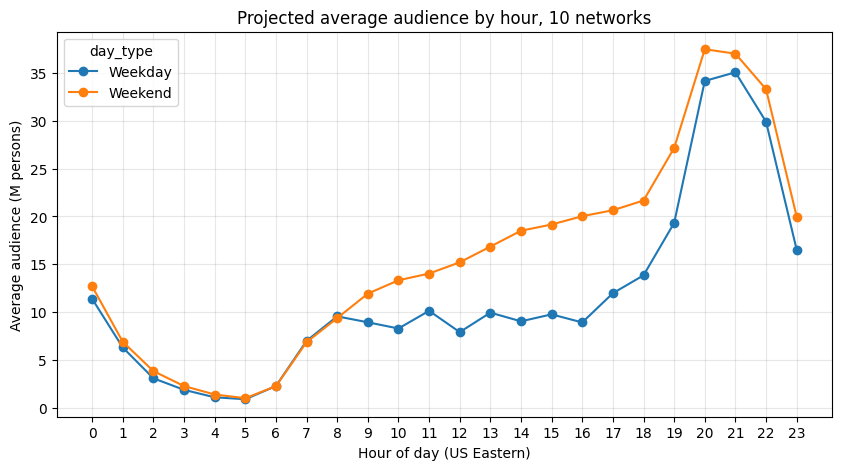

Peak hour, weekdays: 21
Peak hour, weekends: 20
Peak audience, weekdays (M): 35.08
Peak audience, weekends (M): 37.49


In [9]:
# Keep person sessions that start on an October broadcast day
days = pd.Series(daily_weights["broadcast_date"].unique())
pv = person_viewings[person_viewings["broadcast_date"].isin(days)]

# Split every session at hour boundaries: one row per (session, clock hour it touches)
first_hour = pv["start_ts"].dt.floor("h")
n_hours = ((pv["end_ts"].dt.ceil("h") - first_hour) / pd.Timedelta(hours=1)).astype(int)
seg = pv.loc[pv.index.repeat(n_hours), ["start_ts", "end_ts", "weight"]].reset_index()
seg["hour_start"] = seg["start_ts"].dt.floor("h") + pd.to_timedelta(seg.groupby("index").cumcount(), unit="h")
seg["hour_end"] = seg["hour_start"] + pd.Timedelta(hours=1)

# Minutes of the session inside that hour (e.g. 20:50-21:20 -> 10 min in hour 20, 20 min in hour 21)
seg_start = seg["start_ts"].where(seg["start_ts"] > seg["hour_start"], seg["hour_start"])
seg_end = seg["end_ts"].where(seg["end_ts"] < seg["hour_end"], seg["hour_end"])
seg["weighted_min"] = (seg_end - seg_start).dt.total_seconds() / 60 * seg["weight"]

# Weekday / weekend by broadcast day (Friday 01:00 still belongs to Thursday)
seg["broadcast_date"] = pd.to_datetime((seg["hour_start"] - pd.Timedelta(hours=6)).dt.date)
seg = seg[seg["broadcast_date"].isin(days)]
seg["day_type"] = np.where(seg["broadcast_date"].dt.dayofweek >= 5, "Weekend", "Weekday")
seg["hour"] = seg["hour_start"].dt.hour

n_days = pd.Series(np.where(days.dt.dayofweek >= 5, "Weekend", "Weekday")).value_counts()

# Average audience in an hour = weighted minutes / 60 / number of such days
hourly = seg.groupby(["hour", "day_type"])["weighted_min"].sum().unstack()
hourly = hourly / 60 / n_days / 1e6

hourly.plot(marker="o", figsize=(10, 5))
plt.xticks(range(24))
plt.xlabel("Hour of day (US Eastern)")
plt.ylabel("Average audience (M persons)")
plt.title("Projected average audience by hour, 10 networks")
plt.grid(alpha=0.3)
plt.show()

print("Peak hour, weekdays:", hourly["Weekday"].idxmax())
print("Peak hour, weekends:", hourly["Weekend"].idxmax())
print("Peak audience, weekdays (M):", f'{hourly["Weekday"].max():.2f}')
print("Peak audience, weekends (M):", f'{hourly["Weekend"].max():.2f}')

**Answer:** The weekday peak is at **hour 21** (about 35 M persons) and the weekend peak is one hour earlier, at **hour 20** (about 37.5 M). On weekdays the audience is lowest overnight (about 1 M at 04:00–05:00), stays flat at roughly 8–10 M from 08:00 to 16:00, and then rises sharply into prime time.

The weekend differs mostly in the daytime. From late morning the weekend audience climbs steadily, and in the afternoon it is about twice the weekday level (roughly 18–22 M vs 9–14 M). People are at home, and weekend afternoons carry live sports such as college football and the NFL, which is the likely driver. As a result, the step from daytime to prime time is much smaller on weekends, and the evening peak comes earlier.

## Task 1.3 — Session length

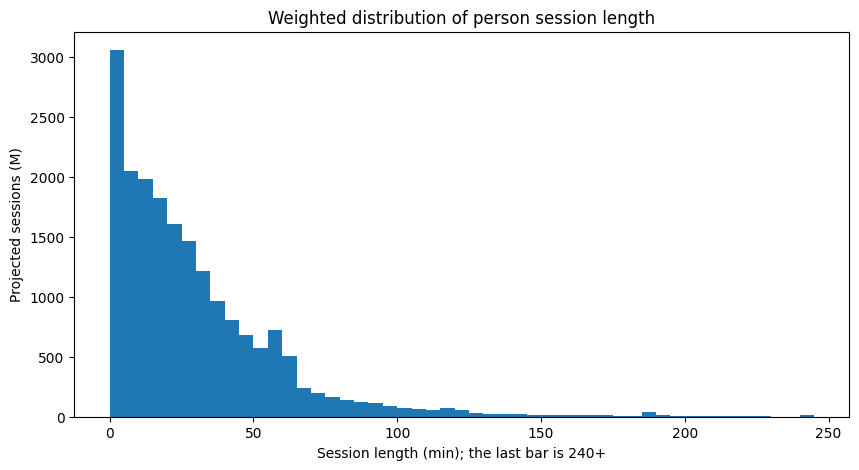

Session length, weighted mean (min): 29.4
Session length, weighted median (min): 21.0


In [10]:
sessions = person_viewings[["minutes", "weight"]]

plt.figure(figsize=(10, 5))
plt.hist(sessions["minutes"].clip(upper=240), bins=range(0, 250, 5), weights=sessions["weight"] / 1e6)
plt.xlabel("Session length (min); the last bar is 240+")
plt.ylabel("Projected sessions (M)")
plt.title("Weighted distribution of person session length")
plt.show()

weighted_mean = (sessions["minutes"] * sessions["weight"]).sum() / sessions["weight"].sum()
weighted_median = weighted_quantile(sessions["minutes"], sessions["weight"], 0.5)

print("Session length, weighted mean (min):", round(weighted_mean, 1))
print("Session length, weighted median (min):", round(weighted_median, 1))

**Answer:** The weighted mean session lasts **29.4 min** and the weighted median **21.0 min**. The distribution is strongly right-skewed: most sessions are fairly short, but a long tail lasts for hours (a whole game or film, or a TV left on). These few long sessions pull the mean up, while the median is not affected by them.

For a client deck I would show the **median**, because it describes a typical session: half of all sessions are shorter than 21 minutes. The mean overstates what a typical viewer does. It is still useful internally, because mean × number of sessions gives total viewing time.

## Task 2 — Program reach curve

Take all October telecasts of *CBS Evening News* (weekdays on CBS).

1. For each telecast compute the household rating, the P2+ rating and the projected audience in millions of persons.
2. In air order, compute the cumulative reach after each telecast for P2+, A18–34 and A18–49, and plot the three curves.
3. Why does cumulative reach keep growing while each telecast's rating stays roughly flat? Which audience does the program reach best, and does that match what you know about who watches network evening news?

In [11]:
cbs_news = programs[(programs["network_code"] == "CBS")
                    & programs["program_name"].str.contains("CBS Evening News", case=False)].sort_values("start_ts")

w = watchers(cbs_news)
w = w.merge(daily_weights[["respondent_id", "broadcast_date", "weight", "group"]],
            on=["respondent_id", "broadcast_date"])          # that day's weight

# Universe each day = weights of everyone in-tab that day
universe = daily_weights.groupby(["broadcast_date", "group"])["weight"].sum().unstack()

audience = w.groupby(["telecast_id", "group"])["weight"].sum().unstack()
tel = cbs_news.set_index("telecast_id")[["broadcast_date", "start_ts"]].join(audience)
tel["HH rating (%)"] = 100 * tel["HH"] / tel["broadcast_date"].map(universe["HH"])
tel["P2+ rating (%)"] = 100 * tel["P2+"] / tel["broadcast_date"].map(universe["P2+"])
tel["Projected audience (M)"] = tel["P2+"] / 1e6
tel[["start_ts", "HH rating (%)", "P2+ rating (%)", "Projected audience (M)"]].round(2)

,start_ts,HH rating (%),P2+ rating (%),Projected audience (M)
telecast_id,,,,
1003837,2024-10-01 18:30:00,3.47,1.67,5.28
1003857,2024-10-02 18:30:00,3.07,1.48,4.68
1003877,2024-10-03 18:30:00,2.99,1.47,4.68
1003896,2024-10-04 18:30:00,3.00,1.51,4.81
1003936,2024-10-07 18:30:00,3.06,1.52,4.83
1003952,2024-10-08 18:30:00,3.17,1.57,4.97
1003970,2024-10-09 18:30:00,2.98,1.48,4.70
1003985,2024-10-10 18:30:00,3.38,1.62,5.13
1004001,2024-10-11 18:30:00,3.09,1.48,4.69


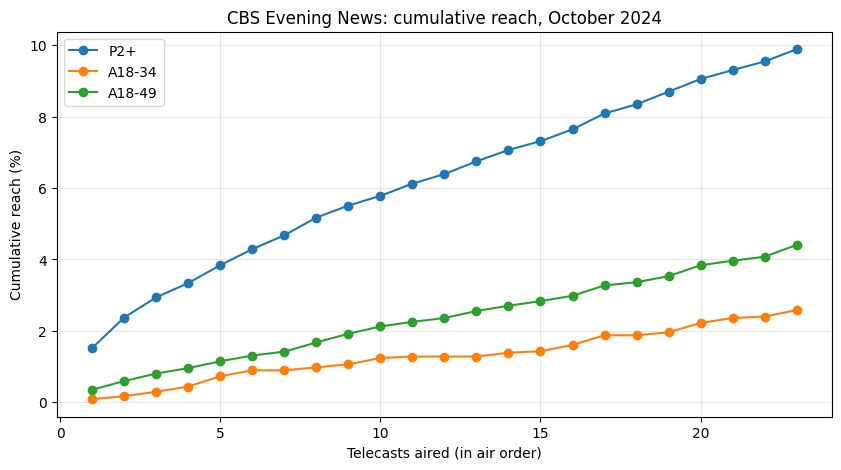

Telecasts of the program: 23
Average household rating (%): 3.2
Average P2+ rating (%): 1.6
Average projected audience (M): 4.93
Final reach P2+ (%): 9.9
Final reach A18-34 (%): 2.6
Final reach A18-49 (%): 4.4
Reach P2+ after the first telecast (%): 1.5


In [12]:
# Cumulative reach: for each person, the first telecast (in air order) they watched
order = dict(zip(cbs_news["telecast_id"], range(1, len(cbs_news) + 1)))
pw = w[w["group"] == "P2+"]
persons["first_seen"] = pw["telecast_id"].map(order).groupby(pw["respondent_id"]).min()

groups = {
    "P2+": persons,
    "A18-34": persons[persons["age"].between(18, 34)],
    "A18-49": persons[persons["age"].between(18, 49)],
}
reach = pd.DataFrame({
    name: [100 * g.loc[g["first_seen"] <= k, "monthly_weight"].sum() / g["monthly_weight"].sum()
           for k in order.values()]
    for name, g in groups.items()
}, index=list(order.values()))

reach.plot(marker="o", figsize=(10, 5))
plt.xlabel("Telecasts aired (in air order)")
plt.ylabel("Cumulative reach (%)")
plt.title("CBS Evening News: cumulative reach, October 2024")
plt.grid(alpha=0.3)
plt.show()

print("Telecasts of the program:", len(cbs_news))
print("Average household rating (%):", round(tel["HH rating (%)"].mean(), 1))
print("Average P2+ rating (%):", round(tel["P2+ rating (%)"].mean(), 1))
print("Average projected audience (M):", round(tel["Projected audience (M)"].mean(), 2))

print("Final reach P2+ (%):", round(reach["P2+"].iloc[-1], 1))
print("Final reach A18-34 (%):", round(reach["A18-34"].iloc[-1], 1))
print("Final reach A18-49 (%):", round(reach["A18-49"].iloc[-1], 1))
print("Reach P2+ after the first telecast (%):", round(reach["P2+"].iloc[0], 1))

**Answer:** The program aired 23 times in October with a very stable audience: a household rating of 2.7–3.6% (3.2% on average), a P2+ rating of 1.3–1.8% (1.6% on average) and about 4.9 M persons per telecast.

**Why reach grows while ratings stay flat.** A rating counts the people watching one telecast, and that number is about the same every evening. Reach counts the *unique* people who have seen the program at least once so far. Each evening's audience is mostly regular viewers, but it also includes occasional viewers who have not been counted yet, and each of them adds to reach. P2+ reach therefore grows from 1.5% after the first telecast to 9.9% after all 23, about 0.4 points per telecast. The curve is still close to a straight line at the end of the month, so the program keeps finding new viewers; it would only flatten once almost every telecast reached people who were already counted.

**Who it reaches best.** Of the three audiences, the program reaches P2+ best (9.9%) and young adults worst: 4.4% of A18–49 and only 2.6% of A18–34. Its A18–34 reach is about a quarter of its P2+ reach, and its A18–49 reach is less than half. Since children are also unlikely to watch evening news, most of the P2+ reach must come from viewers aged 50 and over. This matches what is known about network evening news: its audience is mostly older adults who watch linear TV at the dinner hour, while younger adults get their news online.

## Task 3 — Program frequency

For *The Young and the Restless* (a daily soap on CBS), count for every person who watched how many of its October telecasts they saw: that is the program's frequency. Each person's monthly weight is used, as in the lab rules.

1. Report the projected number of viewers (millions), and the weighted average and median frequency.
2. Plot the frequency distribution in projected viewers: how many millions watched 1, 2, 3, … telecasts.
3. What share of all projected views comes from the most loyal viewers (frequency at or above the weighted 80th percentile, whole frequency levels)? Is the average frequency a fair summary ("the average can lie")?

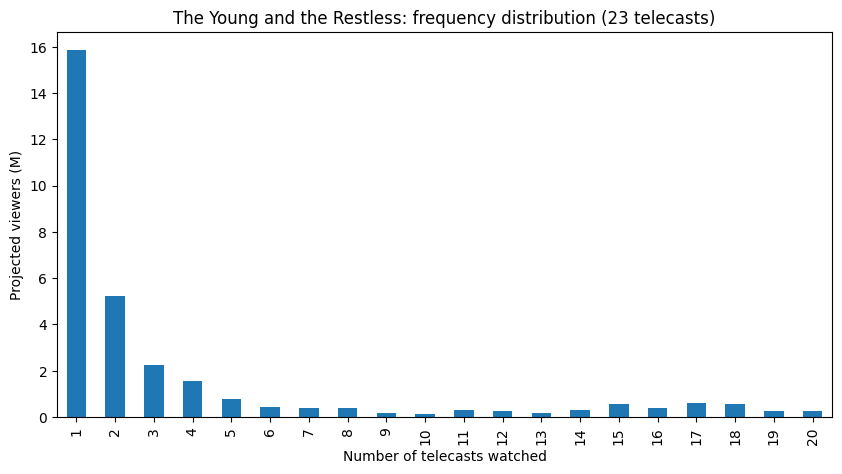

Y&R telecasts in October: 23 | weighted 80th percentile of frequency: 4
Share of viewers who are 'most loyal': 0.243
Projected viewers (M): 30.80
Average frequency (weighted): 3.63
Median frequency (weighted): 1
Share of views from the most loyal viewers: 0.704

Projected viewers (M) by number of telecasts watched:
frequency
1     15.85
2      5.22
3      2.25
4      1.54
5      0.79
6      0.44
7      0.40
8      0.38
9      0.17
10     0.12
11     0.30
12     0.25
13     0.17
14     0.30
15     0.57
16     0.41
17     0.58
18     0.55
19     0.26
20     0.25


In [13]:
yr = programs[(programs["network_code"] == "CBS")
              & programs["program_name"].str.contains("Young and the Restless", case=False)]

yw = watchers(yr)
yw = yw[yw["resp_type"].isin(["R", "L"])]          # persons only

freq = yw.groupby("respondent_id")["telecast_id"].nunique().to_frame("frequency")
freq["weight"] = persons["monthly_weight"]          # monthly weight from the rules

viewers_m = freq["weight"].sum() / 1e6
avg_freq = (freq["frequency"] * freq["weight"]).sum() / freq["weight"].sum()
median_freq = weighted_quantile(freq["frequency"], freq["weight"], 0.5)

# Frequency distribution in projected viewers
dist = freq.groupby("frequency")["weight"].sum() / 1e6
dist.plot(kind="bar", figsize=(10, 5))
plt.xlabel("Number of telecasts watched")
plt.ylabel("Projected viewers (M)")
plt.title(f"The Young and the Restless: frequency distribution ({len(yr)} telecasts)")
plt.show()

# Most loyal viewers: frequency at or above the weighted 80th percentile
p80 = weighted_quantile(freq["frequency"], freq["weight"], 0.8)
views = freq["frequency"] * freq["weight"]
loyal = freq["frequency"] >= p80
loyal_share = views[loyal].sum() / views.sum()

print("Y&R telecasts in October:", len(yr), "| weighted 80th percentile of frequency:", p80)
print("Share of viewers who are 'most loyal':", round(freq.loc[loyal, "weight"].sum() / freq["weight"].sum(), 3))

print("Projected viewers (M):", f"{viewers_m:.2f}")
print("Average frequency (weighted):", round(avg_freq, 2))
print("Median frequency (weighted):", median_freq)
print("Share of views from the most loyal viewers:", round(loyal_share, 3))

print("\nProjected viewers (M) by number of telecasts watched:")
print(dist.round(2).to_string())

**Answer:** *The Young and the Restless* reached **30.80 M** projected viewers in October. The weighted average frequency is **3.63** telecasts, but the weighted median is only **1**.

The audience falls into two very different groups. About 15.9 M people, more than half of all viewers, saw just one episode, and another 5.2 M saw two: these are occasional viewers. At the other end there is a loyal core of regular viewers, visible as a second bump at 15–18 of the 23 telecasts. The weighted 80th percentile of frequency is 4, so the most loyal viewers are everyone who watched 4 or more episodes. They are **24.3%** of viewers but generate **70.4%** of all projected views.

The average frequency is not a fair summary; this is a clear case of "the average can lie". The value 3.63 falls between the two groups and describes almost nobody (only about 1.6 M people watched exactly 4 episodes). It understates how loyal the core audience is and overstates how often a typical viewer watches. The median together with the full distribution describes the audience much better.

## Task 4 — Networks by age and gender

1. For each network compute projected viewing minutes (minutes × weight) for six audiences: M18–34, W18–34, M35–54, W35–54, M55+ and W55+. List the top 5 networks for each audience.
2. Which network has the youngest audience and which the oldest? Measure it as the share of each network's projected minutes coming from 18–34 viewers.
3. Compute the same share once more without weights (raw panel minutes). Why is it different? What does it tell you about who is over- or under-represented in the panel, and what would go wrong if you reported raw panel numbers to a client?
4. Bonus: if you sold ads on the oldest network, how would you pitch it to an advertiser who wants young adults?

In [14]:
pv4 = person_viewings.join(persons[["sex", "age_band"]], on="respondent_id")
pv4["proj_min"] = pv4["minutes"] * pv4["weight"]       # projected minutes = minutes x weight

adults = pv4[pv4["age_band"].isin(["18-34", "35-54", "55+"])].copy()
adults["demo"] = adults["sex"] + adults["age_band"].astype(str)

demo_min = adults.pivot_table(index="network_code", columns="demo", values="proj_min", aggfunc="sum")

for demo in ["M18-34", "W18-34", "M35-54", "W35-54", "M55+", "W55+"]:
    top5 = (demo_min[demo].nlargest(5) / 1e6).round(1)
    top5.index = top5.index.map(network_names).rename("network")
    print(f"Top 5 networks, {demo} (projected minutes, M)")
    print(top5.to_string(), "\n")

Top 5 networks, M18-34 (projected minutes, M)
network
FOX    4386.6
NBC    3910.4
CBS    3044.3
ABC    3010.8
FX     1474.0 

Top 5 networks, W18-34 (projected minutes, M)
network
FOX    4574.4
NBC    4527.6
ABC    3504.9
CBS    2811.2
FX     1383.5 

Top 5 networks, M35-54 (projected minutes, M)
network
FOX    12804.7
NBC    10986.7
ABC     9037.0
CBS     8134.1
FX      2370.8 

Top 5 networks, W35-54 (projected minutes, M)
network
NBC     11639.1
FOX     11161.4
ABC      9438.6
CBS      8162.8
HGTV     3051.8 

Top 5 networks, M55+ (projected minutes, M)
network
CBS                 38274.0
NBC                 34267.4
FOX                 30878.5
ABC                 30793.3
Fox News Channel    27903.7 

Top 5 networks, W55+ (projected minutes, M)
network
CBS                 47120.3
NBC                 41391.9
ABC                 38840.0
FOX                 36914.7
Fox News Channel    31450.7 



In [16]:
# 18-34 share of each network's minutes (all persons P2+ in the denominator), weighted and raw
is_young = pv4["age_band"] == "18-34"
share = pd.DataFrame({
    "weighted": pv4[is_young].groupby("network_code")["proj_min"].sum() / pv4.groupby("network_code")["proj_min"].sum(),
    "raw": pv4[is_young].groupby("network_code")["minutes"].sum() / pv4.groupby("network_code")["minutes"].sum(),
}).fillna(0)
share["difference"] = share["weighted"] - share["raw"]
share.index = share.index.map(network_names)
share = share.sort_values("weighted", ascending=False)
display(share.round(3))

print("Youngest network:", share["weighted"].idxmax())
print("Oldest network:", share["weighted"].idxmin())

,weighted,raw,difference
network_code,,,
FX,0.266,0.232,0.034
Bravo,0.148,0.127,0.021
FOX,0.082,0.075,0.007
Food Network,0.078,0.071,0.007
NBC,0.073,0.068,0.005
ABC,0.064,0.060,0.004
HGTV,0.058,0.052,0.006
CBS,0.051,0.050,0.002
History,0.048,0.044,0.004


Youngest network: FX
Oldest network: Fox News Channel


**Answer:**

**Top 5 by audience.** The four big broadcast networks (FOX, NBC, CBS, ABC) are in the top 5 for every audience, simply because they are the largest. The smaller networks appear only where their audience is concentrated: FX for M18–34, W18–34 and M35–54, HGTV for W35–54, and Fox News Channel for M55+ and W55+. FOX leads both 18–34 audiences and M35–54, NBC leads W35–54, and CBS leads both 55+ audiences.

**Youngest and oldest.** Measured by the share of projected minutes from 18–34 viewers, the youngest network is **FX** (0.266) and the oldest is **Fox News Channel** (0.018).

**Weighted vs raw.** Without weights the 18–34 share is lower on all ten networks (for FX 0.232 instead of 0.266, for Bravo 0.127 instead of 0.148). Weights correct for the panel not matching the US population: a group that is under-represented in the panel gets larger weights, so that it counts for its true size. Because the weighted share is higher everywhere, 18–34s must be under-represented in the panel (young adults are harder to recruit and keep in-tab), and older viewers over-represented. Reporting raw panel numbers to a client would understate young audiences and overstate older ones: every network would look older than it is, and ratings, prices and media plans built on those numbers would be wrong.

**Bonus answer:** Young adults are only 1.8% of Fox News Channel's minutes, but they choose to watch live news with full attention, and they are probably not the same heavy entertainment viewers you already reach on FX and Bravo. Adding Fox News gives your campaign extra reach among young adults instead of more frequency on the same people, and your ad runs inside live programming that viewers do not skip.